# 01 · Data

What the model is trained and evaluated on, what was removed from the published dataset and why,
and how patients are split. Everything here is produced by `thyroid.data.prepare` and
`thyroid.data.splits`; this notebook only reads their output.

**Source:** [Figshare 26067475](https://doi.org/10.6084/m9.figshare.26067475) (CC BY 4.0), thyroid
ultrasound frames from two collection batches, each patient labelled **benign or malignant by
histopathology**.

In [1]:
import csv, json, os
from collections import Counter
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from thyroid.plotting import CLASS_COLORS, SURFACE, use_style

use_style()
report = json.loads(Path("splits/prepare_report.json").read_text())
manifest = pd.read_csv("splits/manifest.csv")
patients = pd.read_csv("splits/patients.csv")
df = manifest.merge(patients, on="patient_id")
df["class"] = df["label"].map({0: "benign", 1: "malignant"})

## What is in the dataset

In [2]:
summary = (df.groupby(["source", "class"])
             .agg(images=("image", "size"), patients=("patient_id", "nunique"))
             .unstack("class"))
summary.loc["total"] = summary.sum()
summary

images           patients          
class  benign malignant   benign malignant
source                                    
batch1   1992      3914      216       383
batch2    616      1291       66       120
total    2608      5205      282       503

In [3]:
per_patient = df.groupby("patient_id").agg(n=("image", "size"), source=("source", "first"))
print(f"{len(df)} images from {df.patient_id.nunique()} patients, "
      f"{df.label.mean():.0%} malignant (images), "
      f"{df.groupby('patient_id').label.first().mean():.0%} malignant (patients)")
print(f"images per patient: median {per_patient.n.median():.0f}, max {per_patient.n.max()}")

7813 images from 785 patients, 67% malignant (images), 64% malignant (patients)
images per patient: median 9, max 31


Malignant patients are the majority (about two thirds). This is why accuracy is a poor headline
metric here: always answering "malignant" already gets ~67% of images right. The evaluation reports AUROC,
sensitivity, specificity and balanced accuracy, with the majority-class accuracy alongside.

## What was removed and why

The published archives need cleaning before use. The table lists every image that did not make it
into the manifest.

In [4]:
pd.DataFrame(sorted(report["dropped"].items(), key=lambda kv: -kv[1]),
             columns=["reason", "images"]).set_index("reason")

,images
reason,
batch2: files in patient folders not listed as ultrasound frames,773
near-duplicate within one patient (extra copies dropped),123
batch1: image without label,21
batch2: image without label,10
near-duplicate across different patients (all copies dropped),10
batch2: missing or corrupt in the published archive,6


- **Report scans.** Batch 2 patient folders also contain scanned pathology reports (A4 pages).
  Only the frames listed in `batch2_image.csv` are ultrasound images.
- **Ambiguous names.** Batch 1 links images to labels by patient *name*. Names shared by patients
  with the same label are merged into one group, which is safe for splitting. Names shared by
  patients with different labels would make the label ambiguous and would be dropped (none of
  their images appear in the image list).
- **Near-duplicates** (dHash distance ≤ 2) are repeated captures of the same frame. Within one
  patient the extra copies are removed; the same image under two different patients cannot be
  attributed, so all copies go.
- **Corrupt files.** Six frames of one patient cannot be decompressed from the published zip
  (the archive's MD5 matches Figshare, so the damage is upstream).

## Images per patient

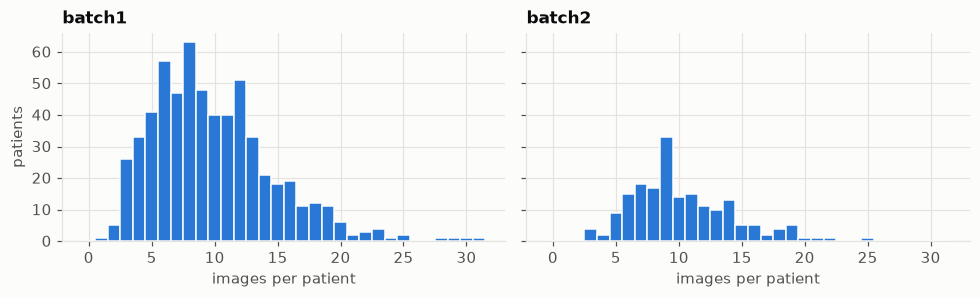

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
bins = np.arange(0, per_patient.n.max() + 2) - 0.5
for ax, source in zip(axes, ["batch1", "batch2"]):
    ax.hist(per_patient.n[per_patient.source == source], bins=bins, color=CLASS_COLORS["benign"],
            edgecolor=SURFACE, linewidth=1)
    ax.set_title(source)
    ax.set_xlabel("images per patient")
axes[0].set_ylabel("patients")
fig.tight_layout()

Every patient contributes several frames, often of the same nodule from different angles. Splitting
by image would put near-identical views of one nodule into both training and evaluation, which is
the main flaw of the original thesis setup. Here **all frames of a patient stay in one split**.

## Patient-level split

157 patients (~20%) are held out as the test set and are not used for any decision: not for early
stopping, not for the decision threshold, not for model choice. The rest is divided into 5
cross-validation folds. All splits are stratified on source × label.

In [6]:
split_table = (df.groupby("split")
                 .agg(patients=("patient_id", "nunique"), images=("image", "size"),
                      malignant=("label", "mean"), batch2=("source", lambda s: (s == "batch2").mean()))
                 .reindex(["fold0", "fold1", "fold2", "fold3", "fold4", "test"]))
assert df.groupby("patient_id").split.nunique().max() == 1, "a patient is in two splits"
split_table.style.format({"malignant": "{:.1%}", "batch2": "{:.1%}"})

,patients,images,malignant,batch2
split,,,,
fold0,126,1215,65.7%,24.1%
fold1,126,1293,64.4%,23.2%
fold2,126,1255,68.0%,23.9%
fold3,125,1340,66.0%,24.6%
fold4,125,1237,67.3%,26.5%
test,157,1473,68.2%,24.2%


## Examples

Random frames per class. The top strip of every frame carries the scan date, time and an exam
number, so it is masked here.

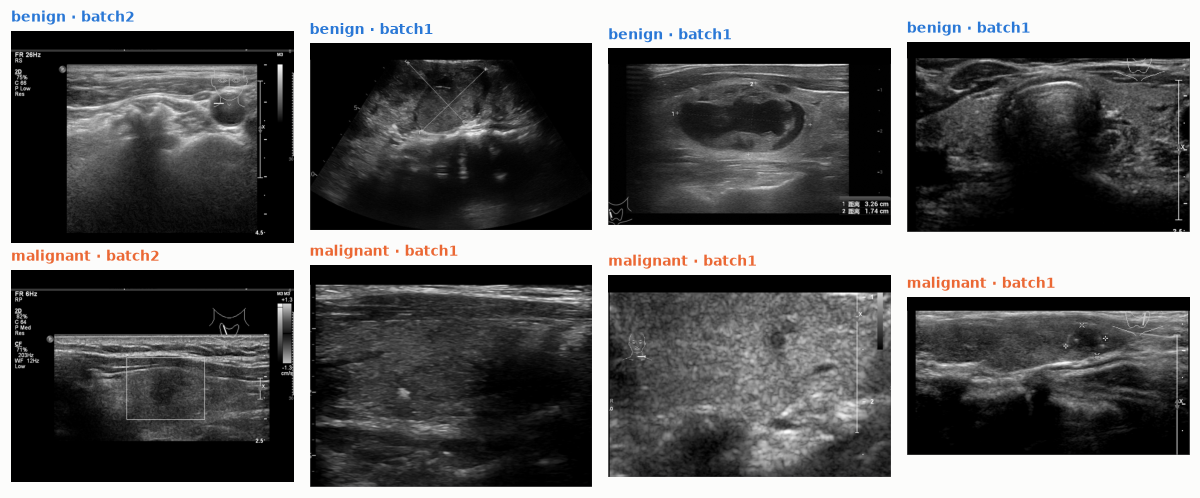

In [7]:
rng = np.random.default_rng(7)
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6))
for row, cls in enumerate(["benign", "malignant"]):
    picks = df[df["class"] == cls].sample(4, random_state=int(rng.integers(1e6)))
    for ax, (_, r) in zip(axes[row], picks.iterrows()):
        img = np.asarray(Image.open(f"data/processed/images/{r.image}"), dtype=np.uint8).copy()
        img[: int(img.shape[0] * 0.09)] = 0
        ax.imshow(img, cmap="gray")
        ax.set_title(f"{cls} · {r.source}", color=CLASS_COLORS[cls], fontsize=9)
        ax.axis("off")
fig.tight_layout()

### Watch-outs for training

- **Burned-in overlays.** Frames contain the scanner's UI: vendor logo (Mindray, Philips),
  acquisition parameters, body-marker icons, and sometimes **calipers** (`+ — +`) or a
  **colour-Doppler box** placed by the sonographer. Both are added to nodules that were measured
  or examined more closely, which correlates with suspicion, so a model can learn to look for
  them instead of the nodule. Grad-CAM in `02_results` checks
  where the models look.
- **Two batches, different equipment.** Batch 1 and batch 2 differ in scanner and layout. Both
  are present in every split in the same proportion, so this is not a train/test shift, but
  results are also reported per batch.
- **Frame-level labels are patient-level.** The histopathology label belongs to the patient, not
  to each frame, so some frames may show tissue other than the diagnosed nodule. Patient-level
  metrics (mean score over a patient's frames) are reported next to image-level ones.